# Second-Order Linear ODEs: Damped SHM and RK4

**References:** `Notes/lec9.pdf`, `Notes/lec10.pdf`, `Notes/SHM_rk4.ipynb` (Professor code), `n/Simple Harmonic Ocilator.ipynb`, `Notes/Quiz2/08_ODE_Systems_and_Nonlinear_Solvers.ipynb`

## Concept & Formulas
Damped harmonic oscillator equation: $m\frac{d^2x}{dt^2} + \gamma\frac{dx}{dt} + kx = 0$.

- **Convert to 1st-Order System:** Let $y_0 = x$ and $y_1 = v = \frac{dx}{dt}$, so:
  $$\frac{dy_0}{dt} = y_1, \qquad \frac{dy_1}{dt} = -\frac{\gamma}{m}y_1 - \frac{k}{m}y_0$$
- **Three Damping Regimes** (let $\omega_0 = \sqrt{k/m}$ and $b = \gamma/(2m)$):
  1. Underdamped ($b < \omega_0$): decays with oscillations.
  2. Critically damped ($b = \omega_0$): fastest decay without oscillation.
  3. Overdamped ($b > \omega_0$): slow monotonic decay (mass term $m\ddot{x}$ becomes small over long timescales $\tau = \gamma/k$).
- **RK4 Method:** Evaluates 4 slopes $k_1, k_2, k_3, k_4$ per step and updates $y_{n+1} = y_n + \frac{\Delta t}{6}(k_1 + 2k_2 + 2k_3 + k_4)$ — accuracy $O(\Delta t^4)$.
- **Limitations of Simple Euler on SHM:** Simple Euler adds artificial energy every step, so an undamped oscillator ($\gamma=0$) spirals outward instead of keeping constant amplitude. RK4 or Euler-Cromer (semi-implicit Euler) avoids this blowup.

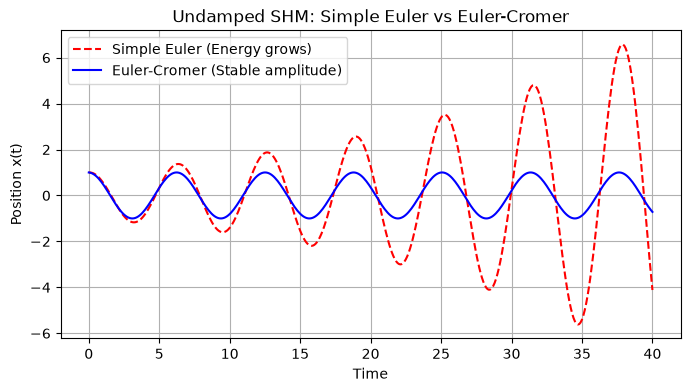

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Undamped SHM (gamma = 0): Simple Euler blows up vs Euler-Cromer stays bounded
k, m = 1.0, 1.0
dt = 0.1
t = np.arange(0, 40 + dt, dt)
n = len(t)

x_eu = np.zeros(n); v_eu = np.zeros(n)
x_ec = np.zeros(n); v_ec = np.zeros(n)  
x_eu[0], v_eu[0] = 1.0, 0.0
x_ec[0], v_ec[0] = 1.0, 0.0

for i in range(n - 1):
    # Simple Euler (uses old v to update x)
    x_eu[i + 1] = x_eu[i] + v_eu[i] * dt
    v_eu[i + 1] = v_eu[i] - (k / m) * x_eu[i] * dt

    # Euler-Cromer (updates v first, then uses NEW v for x)
    v_ec[i + 1] = v_ec[i] - (k / m) * x_ec[i] * dt
    x_ec[i + 1] = x_ec[i] + v_ec[i + 1] * dt

plt.figure(figsize=(8, 4))
plt.plot(t, x_eu, 'r--', label='Simple Euler (Energy grows)')
plt.plot(t, x_ec, 'b-', label='Euler-Cromer (Stable amplitude)')
plt.xlabel('Time')
plt.ylabel('Position x(t)')
plt.title('Undamped SHM: Simple Euler vs Euler-Cromer')
plt.legend()
plt.grid(True)
plt.show()

---
## Professor's Code (`Notes/SHM_rk4.ipynb`) — Annotated
We are solving the **damped harmonic oscillator**:
$$m\frac{d^2x}{dt^2} + \gamma\frac{dx}{dt} + kx = 0$$
RK4 only solves **1st-order** ODEs directly, so we split this 2nd-order ODE into a coupled 2-variable state vector $\mathbf{y} = \begin{bmatrix} x \\ v \end{bmatrix}$ (`y[0]` = position $x$, `y[1]` = velocity $v = \dot{x}$):
$$\frac{d\mathbf{y}}{dt} = \begin{bmatrix} dx/dt \\ dv/dt \end{bmatrix} = \begin{bmatrix} y_1 \\ -\frac{k}{m}y_0 - \frac{\gamma}{m}y_1 \end{bmatrix}$$
At every time step $t_i \to t_i + \Delta t$, RK4 samples **4 slope vectors** $\mathbf{k}_1, \mathbf{k}_2, \mathbf{k}_3, \mathbf{k}_4$ (each having `[dx/dt, dv/dt]`) and takes a Simpson-weighted average $\frac{1}{6}(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4)$, giving $O(\Delta t^4)$ global accuracy.

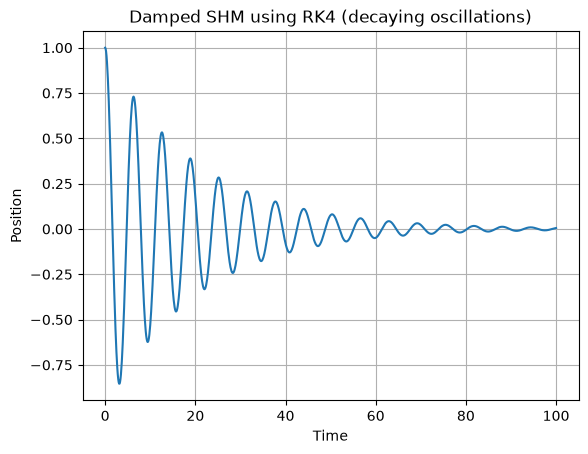

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Physical & numerical parameters ---
k = 1                 # spring constant (restoring force strength)
m = 1                 # mass of the oscillator
gamma = 0.1           # damping coefficient (friction: 0.1 -> underdamped oscillations)
t_end = 100           # final simulation time
dt = 0.1              # time step size h
y0 = np.array([1, 0]) # initial state [x(0), v(0)] = [1, 0]: pulled to x=1, released from rest

t = np.arange(0, t_end + dt, dt)  # time grid from 0 to t_end inclusive
n = len(t)                        # total number of time points

# --- 2. State storage matrix ---
# y has 2 rows and n columns:
#   y[0, i] = position x at time t[i]
#   y[1, i] = velocity v at time t[i]
y = np.zeros((2, n))
y[:, 0] = y0                      # fill column 0 with initial [x(0), v(0)]

# --- 3. Derivative function f(state) = [dx/dt, dv/dt] ---
# Writing f(state) ONCE avoids repeating the ODE formula 4 times inside the loop
def f_shm(state):
    x, v = state
    return np.array([v, -(gamma / m) * v - (k / m) * x])

# --- 4. RK4 time-stepping loop ---
for i in range(n - 1):
    k1 = f_shm(y[:, i])                  # slope at start
    k2 = f_shm(y[:, i] + 0.5 * dt * k1)  # slope at midpoint (using k1)
    k3 = f_shm(y[:, i] + 0.5 * dt * k2)  # improved slope at midpoint (using k2)
    k4 = f_shm(y[:, i] + dt * k3)        # slope at end (using k3)

    # Combine all 4 slopes with Simpson weights (1, 2, 2, 1) / 6 to advance [x, v]
    y[:, i + 1] = y[:, i] + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6

# --- 5. Plot position x(t) = row 0 of y ---
plt.plot(t, y[0, :])
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Damped SHM using RK4 (decaying oscillations)")
plt.grid(True)
plt.show()

---
## Class Notebook Code (`n/Simple Harmonic Ocilator.ipynb`)
Simple Euler and Improved Euler loops for SHM taught in class.

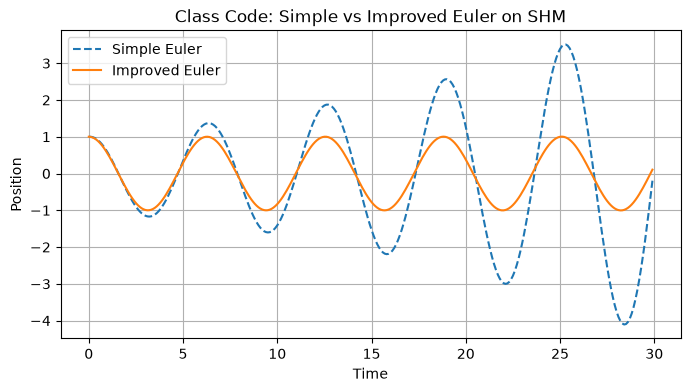

In [3]:
# From n/Simple Harmonic Ocilator.ipynb
def simple_euler_shm(x0, v0, k, m, dt, t_total):
    t = np.arange(0, t_total, dt)
    x = np.zeros(len(t))
    v = np.zeros(len(t))
    x[0], v[0] = x0, v0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + v[i] * dt
        v[i + 1] = v[i] - (k / m) * x[i] * dt
    return t, x, v

def improved_euler_shm(x0, v0, k, m, dt, t_total):
    t = np.arange(0, t_total, dt)
    x = np.zeros(len(t))
    v = np.zeros(len(t))
    x[0], v[0] = x0, v0
    for i in range(len(t) - 1):
        x_mid = x[i] + v[i] * dt / 2
        v_mid = v[i] - (k / m) * x[i] * dt / 2
        x[i + 1] = x[i] + v_mid * dt
        v[i + 1] = v[i] - (k / m) * x_mid * dt
    return t, x, v

t1, x1, v1 = simple_euler_shm(1, 0, 1, 1, 0.1, 30)
t2, x2, v2 = improved_euler_shm(1, 0, 1, 1, 0.1, 30)

plt.figure(figsize=(8, 4))
plt.plot(t1, x1, '--', label='Simple Euler')
plt.plot(t2, x2, '-', label='Improved Euler')
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Class Code: Simple vs Improved Euler on SHM')
plt.legend()
plt.grid(True)
plt.show()